# Import

In [17]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import FortranFile
import smplotlib
from hmf import MassFunction
from astropy.cosmology import FlatLambdaCDM, Planck18
import pandas as pd


# Path 

In [18]:
root = Path("../").resolve()
tree_dir = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/binary_tree_n_progenitors_mh8to14_2_not_mine")
results = root / "Results_600"
zgrid = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/redshift_grid_mh8to14.bin")
models = {"fiducial", "eSFE", "eIMF"}
for model in models:
    print(model, sorted(p.name for p in results.glob(f"{model}_seed*")))

fiducial ['fiducial_seed12345', 'fiducial_seed13579', 'fiducial_seed24680', 'fiducial_seed32889', 'fiducial_seed98765']
eIMF ['eIMF_seed12345', 'eIMF_seed13579', 'eIMF_seed24680', 'eIMF_seed32889', 'eIMF_seed98765']
eSFE ['eSFE_seed12345', 'eSFE_seed13579', 'eSFE_seed24680', 'eSFE_seed32889', 'eSFE_seed98765']


In [19]:
# same cosmology as module_constants.f90
Om, Ob, Ode, h = 0.30966, 0.04897, 0.68885, 0.6766
G, Msun, Mpc = 6.67e-8, 2.0e33, 3.086e24
a_grain, rho_grain, spin = 5.0e-6, 2.25, 0.04
lam_A, c_A = 1500.0, 2.9979e18
H0_cgs = h * 1e7 / Mpc
cosmo = FlatLambdaCDM(H0=100 * h, Om0=Om, Ob0=Ob, Tcmb0=2.7255)
mass_function = MassFunction(z=4.5, cosmo_model=cosmo,
                            sigma_8=0.811, n=0.965,
                            hmf_model="ST", transfer_model="EH",
                            Mmin=7, Mmax=15, dlog10m=0.01,
                            )

# hmf gives m in Msun/h, so the mass in Msun is m / h; densities are per (cMpc/h)^3, so multiply by h^3.
logM_st = np.log10(mass_function.m / h)
# dn/dlnM (not dn/dlog10M = ln(10) dn/dlnM) is the normalisation that reproduces the paper's
# UV LFs and stellar mass functions (Figs. 7 and 9); see fresh.pdf, Sect. 3.
phi_st = mass_function.dndlnm * h**3
dlogM_tree = 0.01          # the 600 trees are spaced by 0.01 dex, from 10^8.00 to 10^13.99 Msun
logM = []
weight = []

In [20]:
with FortranFile(zgrid, "r") as f:
    _ = f.read_ints(np.int32)
    redshifts = f.read_reals(np.float64)

def single_input_tree(p):
    with FortranFile(p, "r") as f:
        _ = int(f.read_ints(np.int32)[0])
        redshift_index_of_halos = f.read_ints(np.int32)
        mass_halos = f.read_reals(np.float64)
        _ = f.read_ints(np.int32)
        _ = f.read_ints(np.int32)
    return redshift_index_of_halos, mass_halos

def read_lum_dust(p):
    with FortranFile(p, "r") as f:
        _sfr = f.read_record(np.float64)
        _mstar = f.read_record(np.float64)
        lum_0 = f.read_record(np.float64)
        lum_1 = f.read_record(np.float64)
        lum_2 = f.read_record(np.float64)
        lum_3 = f.read_record(np.float64)
        lum_4 = f.read_record(np.float64)
        lum_5 = f.read_record(np.float64)
        lum_6 = f.read_record(np.float64)
        _gas_pre = f.read_record(np.float64)
        _gas = f.read_record(np.float64)
        dust = f.read_record(np.float64)
    return _sfr, lum_2, dust   # lum_2 is 1500 A (lum_1 is 1300 A)

def Muv_from_Llambda(L_l):
    # AB magnitude (Oke & Gunn 1983): m_AB = -2.5 log10(f_nu / 3631 Jy), with 1 Jy = 1e-23 erg/s/cm^2/Hz.
    # The absolute magnitude is m_AB at d = 10 pc, where f_nu = L_nu / (4 pi d^2).
    L_nu = L_l * (lam_A ** 2) / c_A                    # erg/s/A -> erg/s/Hz, at 1500 A
    d_10pc = 10.0 * 3.0857e18                          # 10 pc in cm
    f_nu = L_nu / (4.0 * np.pi * d_10pc ** 2)          # erg/s/cm^2/Hz
    M = -2.5 * np.log10(f_nu / 3631e-23)
    return M

def tau_uv(mass_halos, z, dust):
    Hz = H0_cgs * np.sqrt(Om * (1 + z) ** 3 + Ode)
    vc = (10.0 * G * mass_halos * Msun * Hz) ** (1.0 / 3.0)
    rvir = G * mass_halos * Msun / vc ** 2
    rgas = 4.5 * spin * rvir * (1 + z) / 6
    tau = 3.0 * dust * Msun / (4.0 * np.pi * rgas ** 2 * a_grain * rho_grain)
    return tau

def transmit(tau):
    f = np.ones_like(tau, dtype=float)
    f[tau > 1e-6] = -np.expm1(-tau[tau > 1e-6]) / tau[tau > 1e-6]
    return f
    

In [21]:
def uv_lf_single_run(results):
    hist_int = {z_i: np.zeros(len(bins_magnitude) - 1) for z_i in z_use}
    hist_obs = {z_i: np.zeros(len(bins_magnitude) - 1) for z_i in z_use}
    for outp in sorted(results.glob("merger_tree_out_*")):
        tree_id = int(outp.name.split("_")[-1])
        inp = tree_dir / f"merger_tree_{tree_id:05d}"
        redshift_index_of_halos, mass_halos = single_input_tree(inp)
        _sfr, lum_uv, dust = read_lum_dust(outp)
        w = np.interp(np.log10(mass_halos[0]), logM_st, phi_st) * dlogM_tree
        for z_t, z_i in z_use.items():          # z_use: panel redshift -> snapshot index
            sel = redshift_index_of_halos == z_i
            z = redshifts[z_i - 1]
            ww = np.full(sel.sum(), w)
            M_int = Muv_from_Llambda(lum_uv[sel])
            M_obs = Muv_from_Llambda(lum_uv[sel] * transmit(tau_uv(mass_halos[sel], z, dust[sel])))
            hist_int[z_t] += np.histogram(M_int, bins=bins_magnitude, weights=ww)[0]
            hist_obs[z_t] += np.histogram(M_obs, bins=bins_magnitude, weights=ww)[0]
    return hist_int, hist_obs


In [22]:
# panels of figure7.ipynb: first snapshot at or above z up to z = 12, then the closest
z_targets = [5, 7, 8, 9, 10, 11, 12, 14]
z_use = {zt: int(np.argmax(redshifts >= zt)) + 1 if zt <= 12 else int(np.argmin(np.abs(redshifts - zt))) + 1 for zt in z_targets}
bins_magnitude = np.arange(-25.0, -12.5, 0.5)
dM = np.diff(bins_magnitude)
centers = 0.5 * (bins_magnitude[:-1] + bins_magnitude[1:])

In [23]:
luminosity_function = {}
for model in models:
    seeds = [uv_lf_single_run(result) for result in sorted(results.glob(f"{model}_seed*"))]
    if not seeds:
        continue
    else:
        luminosity_function[model] = {name: dict(
            int_mean=np.mean([s[0][name] for s in seeds], axis=0),
            obs_mean=np.mean([s[1][name] for s in seeds], axis=0),
            obs_min=np.min([s[1][name] for s in seeds], axis=0),
            obs_max=np.max([s[1][name] for s in seeds], axis=0)) for name in z_use}
        

In [24]:
obs = pd.read_csv("../observations_jwst/UV_luminosity_function/uvlf_observations.csv")
m1500_col, phi_col = "M1500 [mag]", "log10 Phi [cMpc^-3 mag^-1]"
locol, hicol = "lower uncertainty (log10)", "upper uncertainty (log10)"
survey_marker = {
    "Bouwens+21": "o",
    "Bouwens+22b": "o",
    "Harikane+22a_noAGN": "^",
    "Donnan+23": "o",
    "Atek+15": "D",
    "Bowler+17": "o",
    "Harikane+24a": "x",
    "Adams+24": "D",
    "Willott+24": "p",
    "Bouwens+23a": "o",
    "Bouwens+23a_solid": "o",
    "Bouwens+23a_robust": "o",
    "Bouwens+23b": "o",
    "Bouwens+231": "o",
    "Donnan+24": "o",
    "Finkelstein+24": "s",
    "Harikane+23": "x",
    "Harikane+24b": "x",
    "Perez-Gonzales+23": "x",
    "Leung+23": "o",
    "McLeod+24": "D",
    "Casey+24": "o",
    "Naidu+22b": "x",
    "Robertson+24": "D",
    "Whitler+25": "s",
    "Kokorev+25": "D",
    "Atek+18": "D",
    "Oesch+18": "o",
}

sources = list(obs["Source"].unique())
cmap = plt.get_cmap("tab20")
survey_color = {src: cmap(i / len(sources)) for i, src in enumerate(sources)}

def plot_one_survey(ax, table, source_name):
    marker = survey_marker.get(source_name, "o")
    color = survey_color[source_name]
    M = table[m1500_col].to_numpy()
    logphi = table[phi_col].to_numpy()
    err_lo = table[locol].to_numpy().astype(float)
    err_hi = table[hicol].to_numpy().astype(float)
    err_lo = np.where(err_lo == 999, 0, err_lo)
    err_hi = np.where(err_hi == 999, 0, err_hi)
    ax.errorbar(M, logphi, yerr=[err_lo, err_hi], fmt=marker, color=color, label=source_name, ms=5, lw=0.8)


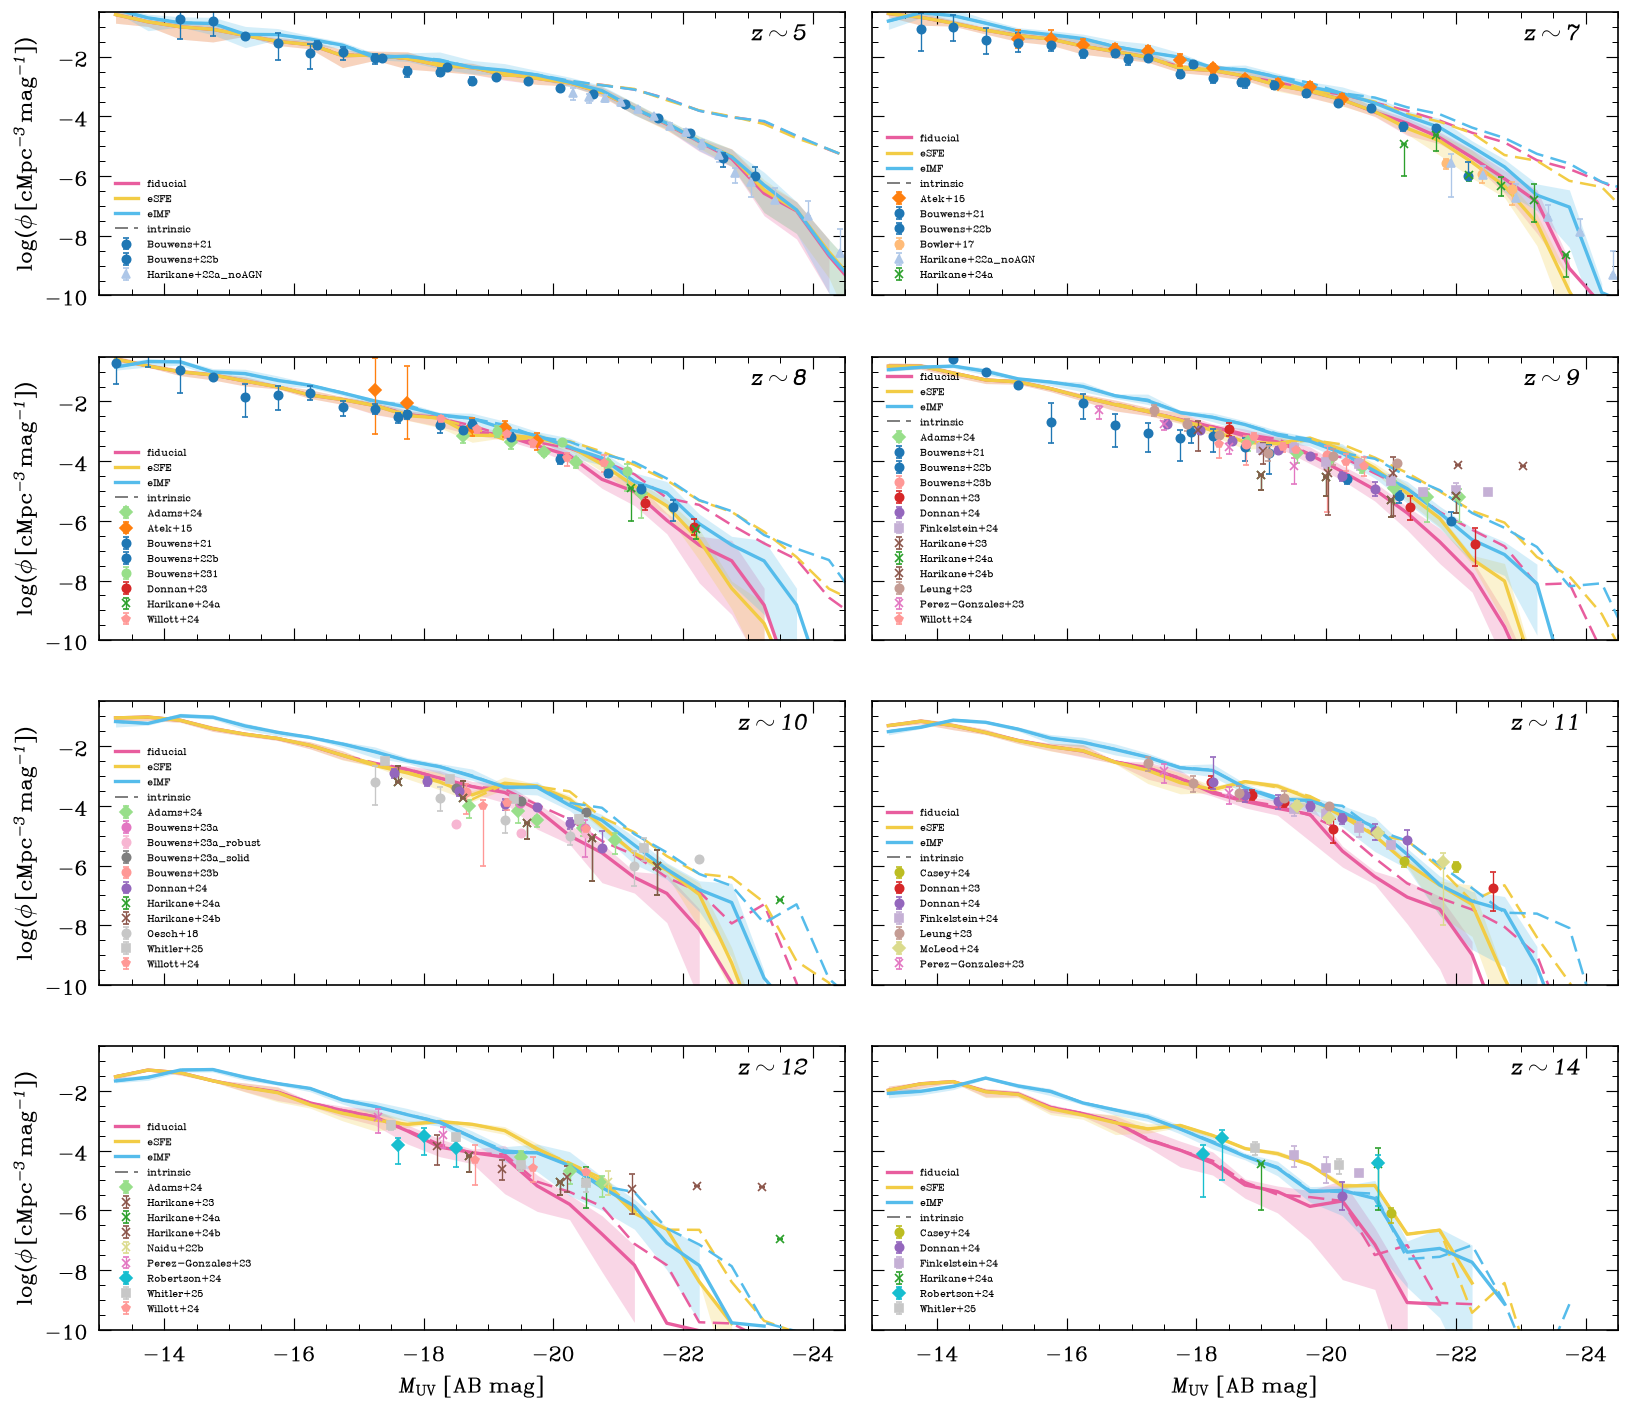

In [39]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True, sharey=True)
model_color = {"fiducial": "#E85D9E", "eSFE": "#F2CC45", "eIMF": "#55BCEB"}
for ax, current_z in zip(axes.ravel(), z_use):
    for model, color in model_color.items():
        if model not in luminosity_function:
            continue
        p = luminosity_function[model][current_z]
        ax.plot(centers, np.log10(p["int_mean"]/dM), "--", color=color, lw=1.5)
        ax.plot(centers, np.log10(p["obs_mean"]/dM), "-", color=color, lw=2, label=model)
        ax.fill_between(centers, np.log10(p["obs_min"]/dM), np.log10(p["obs_max"]/dM), color=color, alpha=0.25, lw=0)
    ax.plot([], [], "--", color="0.5", label="intrinsic")
    at_this_z = obs[np.isclose(obs["z"], current_z)]
    for source_name, source_rows in at_this_z.groupby("Source"):
        plot_one_survey(ax, source_rows, source_name)
    ax.set_xlim(-13, -24.5)
    ax.set_ylim(-10, -0.5)
    ax.text(0.95, 0.9, rf"$z \sim {current_z}$", transform=ax.transAxes, ha="right", fontsize=16)
    ax.legend(frameon=False, fontsize=7, loc=3)

for ax in axes[-1, :]:
    ax.set_xlabel(r"$M_{\rm UV}$ [AB mag]")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\log(\phi\,[{\rm cMpc}^{-3}\,{\rm mag}^{-1}])$")
fig.tight_layout()
fig.savefig("uvlf.png", dpi=200)
plt.show()